In [ ]:
from pathlib import Path
import torch
from torchvision.models import vgg16

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

# Load the pretrained VGG-16 weights.
model = vgg16(weights=None)
weights_path = Path("checkpoints/pretrained_vgg.pt")
state_dict = torch.load(
    weights_path, map_location="cpu", weights_only=True
)
model.load_state_dict(state_dict)

# Keep only the convolutional layers and freeze them.
encoder = model.features
encoder.requires_grad_(False)
encoder.eval()
encoder = encoder.to(device)

del model, state_dict

# Check the output dimensions with a dummy image.
with torch.inference_mode():
    features = encoder(torch.zeros(1, 3, 224, 224, device=device))
    image_vector = features.mean(dim=(2, 3))


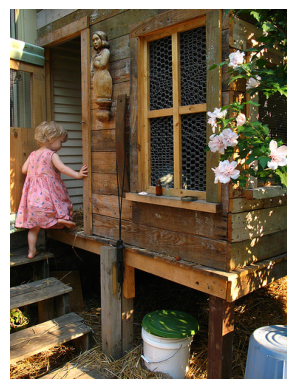

In [6]:
from collections import defaultdict
from PIL import Image
import matplotlib.pyplot as plt

data_dir = Path("data/flickr8k")
image_dir = data_dir / "Flicker8k_Dataset"

captions = defaultdict(list)

with open(data_dir / "Flickr8k.token.txt", encoding="utf-8") as f:
    for line in f:
        image_id, caption = line.strip().split("\t", 1)
        filename = image_id.rsplit("#", 1)[0]
        captions[filename].append(caption)

filename = next(iter(captions))

plt.imshow(Image.open(image_dir / filename).convert("RGB"))
plt.axis("off")
plt.show()


In [27]:
import shutil

checkpoint_dir = Path("checkpoints")
baseline_path = checkpoint_dir / "baseline_3000.pt"

if not baseline_path.exists():
    shutil.copy2(
        checkpoint_dir / "best_caption_decoder.pt",
        baseline_path,
    )

baseline = torch.load(
    baseline_path,
    map_location="cpu",
    weights_only=True,
)

In [28]:
import random

def load_split(filename):
    with open(data_dir / filename) as f:
        names = [line.strip() for line in f if line.strip()]

    return [
        name for name in names
        if name in captions and (image_dir / name).is_file()
    ]

train_images = load_split("Flickr_8k.trainImages.txt")
val_images = baseline["val_images"]
test_images = baseline["test_images"]

assert set(train_images).isdisjoint(val_images)
assert set(train_images).isdisjoint(test_images)
assert set(val_images).isdisjoint(test_images)

In [29]:
import re
from collections import Counter

def tokenize(caption):
    return re.findall(r"[a-z]+", caption.lower())

word_counts = Counter(
    word
    for filename in train_images
    for caption in captions[filename]
    for word in tokenize(caption)
)

vocab = ["<pad>", "<bos>", "<eos>", "<unk>"] + sorted(
    word for word, count in word_counts.items() if count >= 2
)

word_to_idx = {word: idx for idx, word in enumerate(vocab)}
idx_to_word = {idx: word for word, idx in word_to_idx.items()}

PAD_ID, BOS_ID, EOS_ID, UNK_ID = range(4)
MAX_WORDS = 25

def encode_caption(caption):
    words = tokenize(caption)[:MAX_WORDS]
    return (
        [BOS_ID]
        + [word_to_idx.get(word, UNK_ID) for word in words]
        + [EOS_ID]
    )


In [30]:
import torch.nn as nn

class CaptionDecoder(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim=128,
        image_dim=128,
        hidden_dim=256,
    ):
        super().__init__()

        self.image_projection = nn.Sequential(
            nn.Linear(512, image_dim),
            nn.ReLU(),
        )

        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=PAD_ID
        )

        self.lstm = nn.LSTM(
            input_size=embed_dim + image_dim,
            hidden_size=hidden_dim,
            batch_first=True,
        )

        self.output = nn.Linear(hidden_dim, vocab_size)

    def forward(self, image_vectors, input_tokens, state=None):

        word_embeddings = self.embedding(input_tokens)
        image_embeddings = self.image_projection(image_vectors)

        image_embeddings = image_embeddings.unsqueeze(1).expand(
            -1, input_tokens.size(1), -1
        )

        lstm_inputs = torch.cat(
            [word_embeddings, image_embeddings], dim=-1
        )

        hidden, state = self.lstm(lstm_inputs, state)
        logits = self.output(hidden)

        return logits, state


decoder = CaptionDecoder(vocab_size=len(vocab)).to(device)

In [31]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


class ImageDataset(Dataset):
    def __init__(self, filenames):
        self.filenames = filenames

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, index):
        filename = self.filenames[index]
        with Image.open(image_dir / filename) as image:
            image = preprocess(image.convert("RGB"))
        return filename, image


feature_dir = Path("features")
feature_dir.mkdir(exist_ok=True)
cache_path = feature_dir / "vgg16_spatial.pt"

selected_images = sorted(
    set(train_images + val_images + test_images)
)

if cache_path.exists():
    image_features = torch.load(
        cache_path, map_location="cpu", weights_only=True
    )
else:
    image_features = {}

missing_images = sorted(set(selected_images) - set(image_features))

if missing_images:
    loader = DataLoader(
        ImageDataset(missing_images),
        batch_size=8,
        shuffle=False,
        num_workers=0,
    )

    encoder.eval()

    with torch.inference_mode():
        for filenames, images in loader:
            spatial_features = encoder(images.to(device)).cpu()

            for filename, feature in zip(filenames, spatial_features):
                image_features[filename] = feature.clone()

    torch.save(image_features, cache_path)

In [32]:
from torch.nn.utils.rnn import pad_sequence


class CaptionDataset(Dataset):
    def __init__(self, filenames):
        self.pairs = [
            (filename, caption)
            for filename in filenames
            for caption in captions[filename]
        ]

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        filename, caption = self.pairs[index]

        # Average the 7 × 7 spatial grid into a 512-dimensional vector.
        image_vector = image_features[filename].mean(dim=(1, 2))

        tokens = torch.tensor(
            encode_caption(caption), dtype=torch.long
        )

        return image_vector, tokens


def collate_captions(batch):
    image_vectors, token_sequences = zip(*batch)

    image_vectors = torch.stack(image_vectors)

    input_tokens = pad_sequence(
        [tokens[:-1] for tokens in token_sequences],
        batch_first=True,
        padding_value=PAD_ID,
    )

    target_tokens = pad_sequence(
        [tokens[1:] for tokens in token_sequences],
        batch_first=True,
        padding_value=PAD_ID,
    )

    return image_vectors, input_tokens, target_tokens


train_loader = DataLoader(
    CaptionDataset(train_images),
    batch_size=32,
    shuffle=True,
    collate_fn=collate_captions,
    num_workers=0,
    generator=torch.Generator().manual_seed(42),
)

val_loader = DataLoader(
    CaptionDataset(val_images),
    batch_size=32,
    shuffle=False,
    collate_fn=collate_captions,
    num_workers=0,
)

In [34]:
import time

torch.manual_seed(42)

decoder = CaptionDecoder(vocab_size=len(vocab)).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)
optimizer = torch.optim.Adam(decoder.parameters(), lr=1e-3)

checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(exist_ok=True)
model_path = checkpoint_dir / "caption_decoder_6000.pt"

In [35]:
def run_epoch(loader, training):
    decoder.train(training)

    total_loss = 0.0
    total_correct = 0
    total_tokens = 0

    with torch.set_grad_enabled(training):
        for image_vectors, input_tokens, target_tokens in loader:
            image_vectors = image_vectors.to(device)
            input_tokens = input_tokens.to(device)
            target_tokens = target_tokens.to(device)

            if training:
                optimizer.zero_grad()

            logits, _ = decoder(image_vectors, input_tokens)

            loss = criterion(
                logits.reshape(-1, len(vocab)),
                target_tokens.reshape(-1),
            )

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    decoder.parameters(), max_norm=5.0
                )
                optimizer.step()

            mask = target_tokens != PAD_ID
            token_count = mask.sum().item()

            predictions = logits.argmax(dim=-1)
            correct = ((predictions == target_tokens) & mask).sum().item()

            total_loss += loss.item() * token_count
            total_correct += correct
            total_tokens += token_count

    return (
        total_loss / total_tokens,
        100 * total_correct / total_tokens,
    )

In [36]:
EPOCHS = 20
PATIENCE = 4

best_val_loss = float("inf")
epochs_without_improvement = 0
history = []

for epoch in range(1, EPOCHS + 1):
    start = time.perf_counter()

    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)

    elapsed = time.perf_counter() - start

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
        "seconds": elapsed,
    })

    print(
        f"Epoch {epoch:02d} | "
        f"train loss {train_loss:.3f}, acc {train_acc:.1f}% | "
        f"val loss {val_loss:.3f}, acc {val_acc:.1f}% | "
        f"{elapsed:.1f}s"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save({
            "model_state": {
                name: tensor.detach().cpu()
                for name, tensor in decoder.state_dict().items()
            },
            "model_config": {
                "vocab_size": len(vocab),
                "embed_dim": 128,
                "image_dim": 128,
                "hidden_dim": 256,
            },
            "vocab": vocab,
            "max_words": MAX_WORDS,
            "train_images": train_images,
            "val_images": val_images,
            "test_images": test_images,
            "epoch": epoch,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
        },model_path)

    else:
        epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print("Early stopping.")
            break

Epoch 01 | train loss 4.125, acc 29.1% | val loss 3.502, acc 33.6% | 18.1s
Epoch 02 | train loss 3.224, acc 36.4% | val loss 3.181, acc 36.4% | 17.7s
Epoch 03 | train loss 2.910, acc 39.2% | val loss 3.044, acc 38.0% | 17.4s
Epoch 04 | train loss 2.707, acc 41.3% | val loss 3.002, acc 38.4% | 17.5s
Epoch 05 | train loss 2.549, acc 43.0% | val loss 2.963, acc 39.0% | 17.5s
Epoch 06 | train loss 2.418, acc 44.5% | val loss 2.960, acc 38.8% | 17.8s
Epoch 07 | train loss 2.303, acc 45.9% | val loss 2.966, acc 38.6% | 18.6s
Epoch 08 | train loss 2.200, acc 47.5% | val loss 2.988, acc 38.8% | 17.2s
Epoch 09 | train loss 2.108, acc 49.0% | val loss 3.020, acc 38.9% | 17.0s
Epoch 10 | train loss 2.023, acc 50.4% | val loss 3.052, acc 38.6% | 17.0s
Early stopping.


In [46]:
checkpoint = torch.load(
    checkpoint_dir / "baseline_3000.pt",
    map_location="cpu",
    weights_only=True,
)

decoder = CaptionDecoder(**checkpoint["model_config"]).to(device)
decoder.load_state_dict(checkpoint["model_state"])
decoder.eval()

saved_vocab = checkpoint["vocab"]
saved_word_to_idx = {
    word: idx for idx, word in enumerate(saved_vocab)
}


@torch.inference_mode()
def generate_caption(filename):
    image_vector = (
        image_features[filename]
        .mean(dim=(1, 2))
        .unsqueeze(0)
        .to(device)
    )

    token = torch.tensor(
        [[saved_word_to_idx["<bos>"]]],
        dtype=torch.long,
        device=device,
    )

    state = None
    words = []

    for _ in range(checkpoint["max_words"] + 1):
        logits, state = decoder(image_vector, token, state)

        # Prevent padding and sentence-start tokens from being generated.
        scores = logits[:, -1, :].clone()
        scores[:, saved_word_to_idx["<pad>"]] = -torch.inf
        scores[:, saved_word_to_idx["<bos>"]] = -torch.inf

        next_id = scores.argmax(dim=-1).item()

        if next_id == saved_word_to_idx["<eos>"]:
            break

        words.append(saved_vocab[next_id])
        token = torch.tensor(
            [[next_id]], dtype=torch.long, device=device
        )

    return " ".join(words)

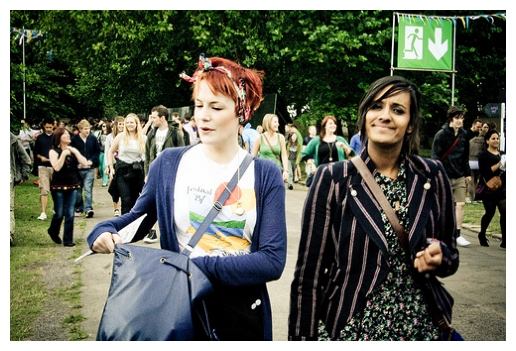

Generated: a woman with a black and white t shirt is standing in front of a man in a crowd
Reference: A man and woman walking down the street .


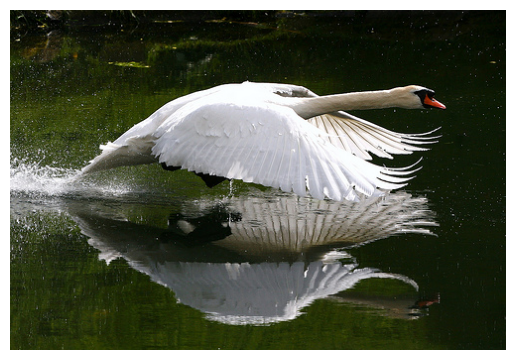

Generated: a white bird is flying over water
Reference: A swan is above water .


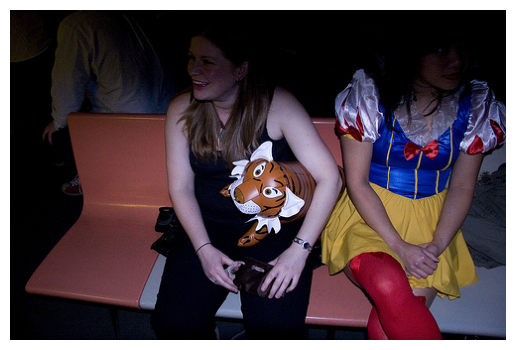

Generated: a woman in a black hat and a white t shirt and a woman in a white shirt and a woman in a white shirt and
Reference: A girl holds a blow-up tiger while another girl is in a costume .


In [47]:
for filename in random.sample(val_images, 3):
    plt.imshow(Image.open(image_dir / filename).convert("RGB"))
    plt.axis("off")
    plt.show()

    print("Generated:", generate_caption(filename))
    print("Reference:", captions[filename][0])

In [48]:
from nltk.translate.bleu_score import corpus_bleu

val_predictions = {
    filename: tokenize(generate_caption(filename))
    for filename in val_images
}

references = [
    [tokenize(caption) for caption in captions[filename]]
    for filename in val_images
]

hypotheses = [
    val_predictions[filename]
    for filename in val_images
]

print(
    f"BLEU-1: {100 * corpus_bleu(references, hypotheses, weights=(1, 0, 0, 0)):.2f}"
)
print(
    f"BLEU-4: {100 * corpus_bleu(references, hypotheses):.2f}"
)

BLEU-1: 50.78
BLEU-4: 13.28
